# Named regions from geometry: `select`

A solver deck names its boundary conditions, contact surfaces and material zones: an inlet, a wall, a bolt hole. A mesh from a mesher, an STL skin or a tetrahedralizer rarely carries them. `select` writes one named region, of points, cells or cell sides, from criteria a script can repeat on the next remesh:

| criterion | argument | selects |
|---|---|---|
| geometry | `box=`, `plane=`, `sphere=` (with `mode` `all` / `any` / `centroid`) | what lies inside |
| data | `where=(array, op, value)` | by a `point_data` or `cell_data` value |
| quality | `quality=(metric, op, value)` | by a `compute_quality` metric |
| component | `component=k` | one loose part, numbered as `split(by="component")` numbers them |
| growth | `seed=(x, y, z)` | the smooth patch nearest a point, bounded by the feature edges |

Criteria given together intersect. The mesh is otherwise unchanged, so selections chain. See `doc/select.md`.

In [1]:
import os
import subprocess
import sys
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp
from meshioplusplus._skin import _CELL_FACES


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')

# Renders the documentation embeds are written here as well as shown.
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')
PALETTE = ['#d9d9d9', '#e63946', '#3b82f6', '#2ec4b6', '#f4a261', '#8338ec']


def show(img, title=None, figsize=(6.5, 4.8), save=None):
    """Embed a rendered RGB screenshot; with `save`, also write doc/public/images/<save>.png."""
    if save:
        try:
            os.makedirs(DOC_IMAGES, exist_ok=True)
            plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
        except Exception as exc:  # pragma: no cover - read-only checkout
            print('doc image not written:', exc)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


def region(mesh, name, kind):
    return next(r for r in mesh.regions if r.name == name and r.kind == kind)


def cell_rows(mesh):
    """(type, connectivity row) per global cell, block-major."""
    return [(b.type, row) for b in mesh.cells for row in np.asarray(b.data)]


def boundary_faces(mesh, labels):
    """Every boundary face of a volume mesh, with the index (1-based) of the first
    side region in `labels` holding it, 0 for none."""
    every = region(mp.select(mesh, '_boundary', 'side', box=(-1e9,) * 3 + (1e9,) * 3), '_boundary', 'side')
    member = {}
    for k, name in enumerate(labels, start=1):
        for c, f in region(mesh, name, 'side').entries:
            member.setdefault((int(c), int(f)), k)
    rows = cell_rows(mesh)
    faces, tags = [], []
    for c, f in every.entries:
        ctype, row = rows[c]
        faces.append(row[list(_CELL_FACES[ctype][f][2])])
        tags.append(member.get((int(c), int(f)), 0))
    return np.array(faces), np.array(tags)


def render_faces(points, faces, tags, labels, title, save=None, camera=None):
    """Quads coloured by label: PyVista, else matplotlib."""
    colours = np.array([PALETTE[t % len(PALETTE)] for t in tags])
    if pv is not None:
        try:
            flat = np.hstack([np.c_[np.full(len(faces), faces.shape[1]), faces]]).ravel()
            surf = pv.PolyData(points, flat)
            surf.cell_data['label'] = tags
            pl = pv.Plotter(off_screen=True, window_size=(900, 680))
            for t in np.unique(tags):
                part = surf.extract_cells(np.flatnonzero(tags == t))
                name = 'unselected' if t == 0 else labels[t - 1]
                pl.add_mesh(part, color=PALETTE[t % len(PALETTE)], show_edges=True,
                            edge_color='#1f4e79', line_width=0.3, label=name)
            pl.add_legend(bcolor='white', size=(0.22, 0.2))
            pl.camera_position = camera or [(-1.5, -1.9, 1.5), (0, 0, 0.05), (0, 0, 1)]
            img = pl.screenshot(return_img=True)
            pl.close()
            show(img, title, save=save)
            return
        except Exception as exc:  # pragma: no cover - GL failure mid-run
            print('PyVista render skipped:', exc)
    fig = plt.figure(figsize=(6.5, 4.8))
    ax = fig.add_subplot(projection='3d')
    ax.add_collection3d(Poly3DCollection(points[faces], facecolors=colours, edgecolors='#1f4e79', linewidths=0.1))
    lo, hi = points.min(axis=0), points.max(axis=0)
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]))
    ax.set_box_aspect(hi - lo)
    ax.view_init(elev=30, azim=-130)
    ax.set_axis_off()
    for t in np.unique(tags):
        ax.plot([], [], 's', color=PALETTE[t % len(PALETTE)], label='unselected' if t == 0 else labels[t - 1])
    ax.legend(loc='upper left')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def render_cells(mesh, name, title, save=None):
    """The boundary faces of the cells in a cell region, highlighted on the others."""
    sel = set(region(mesh, name, 'cell').entries.tolist())
    rows = cell_rows(mesh)
    faces, tags = [], []
    for c, (ctype, row) in enumerate(rows):
        for _t, _n, nodes in _CELL_FACES[ctype]:
            faces.append(row[list(nodes)])
            tags.append(1 if c in sel else 0)
    faces, tags = np.array(faces), np.array(tags)
    # Only faces on the outside of their group: shared by one cell of that group.
    key = [tuple(sorted(f)) + (t,) for f, t in zip(faces.tolist(), tags)]
    count = {}
    for k in key:
        count[k] = count.get(k, 0) + 1
    keep = np.array([count[k] == 1 for k in key])
    render_faces(mesh.points, faces[keep], tags[keep], [name], title, save=save)

## A part to name

A plate with a bolt hole, swept into hexahedra: four quad blocks from the `plate_with_hole` primitive, extruded through four layers. It carries no regions yet.

In [2]:
plate = mp.plate_with_hole(radius=0.25, size=1.0, nt=8, nr=4)
part = mp.extrude(plate, (0.0, 0.0, 0.25), num_layers=4)
part.regions = []
print('blocks :', [(c.type, len(c.data)) for c in part.cells])
print('points :', len(part.points))

blocks : [('hexahedron', 512)]
points : 800


## Boundary patches grown from a point

`seed=` grows a patch from the boundary face nearest a point across every edge whose dihedral angle is at most `feature_angle` (30 degrees by default) — the edges `feature_edges` would not draw. The bolt hole's wall is smooth, so a seed inside the hole takes the whole wall, across the four blocks; a seed above the plate takes its flat top. A box picks the faces of one outer side.

bolt_hole 128 of 512 boundary faces
top       128 of 512 boundary faces
inlet      32 of 512 boundary faces


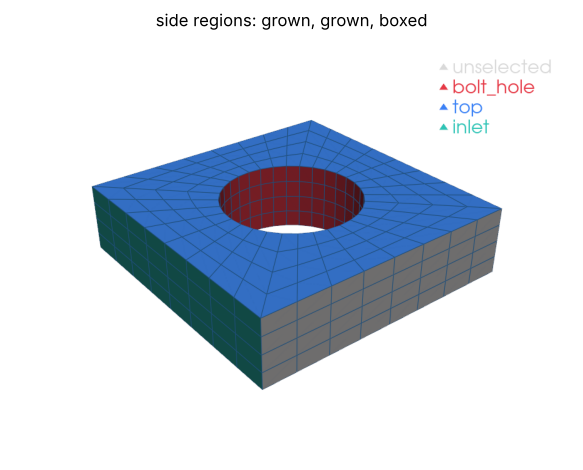

In [3]:
part, hole = mp.select(part, 'bolt_hole', 'side', seed=(0.0, 0.0, 0.1), return_report=True)
part, top = mp.select(part, 'top', 'side', seed=(0.3, 0.3, 1.0), return_report=True)
part, inlet = mp.select(part, 'inlet', 'side', box=(-0.6, -0.6, -1, -0.5 + 1e-9, 0.6, 1), return_report=True)
for name, rep in (('bolt_hole', hole), ('top', top), ('inlet', inlet)):
    print('%-9s %3d of %d boundary faces' % (name, rep['num_selected'], rep['num_candidates']))
labels = ['bolt_hole', 'top', 'inlet']
faces, tags = boundary_faces(part, labels)
render_faces(part.points, faces, tags, labels, 'side regions: grown, grown, boxed', save='select')

The growth stops where the wall meets the top and the bottom: those edges are 90 degree creases. `normal_tolerance=` bounds how far a patch may turn instead — half the hole's wall, here.

the whole wall: 128 faces; within 60 degrees of the seed: 44


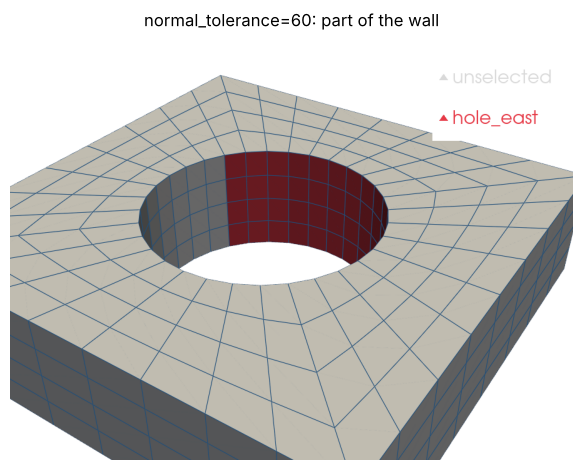

In [4]:
part, half = mp.select(part, 'hole_east', 'side', seed=(0.3, 0.0, 0.1), normal_tolerance=60, return_report=True)
print('the whole wall: %d faces; within 60 degrees of the seed: %d' % (hole['num_selected'], half['num_selected']))
faces, tags = boundary_faces(part, ['hole_east'])
render_faces(part.points, faces, tags, ['hole_east'], 'normal_tolerance=60: part of the wall',
             camera=[(-1.1, -0.8, 1.1), (0.1, 0, 0.1), (0, 0, 1)])

## Cells by geometry, data and quality

A cell region from a half-space, reducing each cell to its centroid; then the same plate jittered, its worst cells selected by quality. Criteria given together intersect: the bad cells on the east side only.

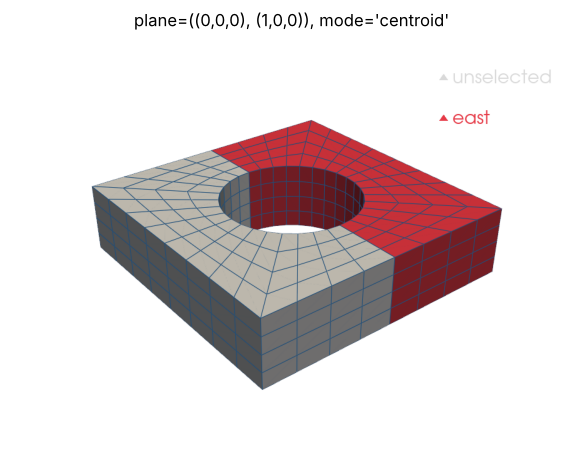

scaled Jacobian < 0.6: 27 cells, 11 of them east


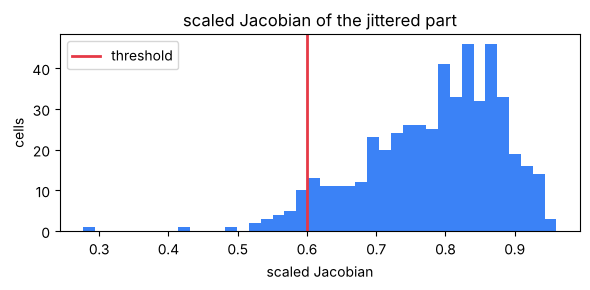

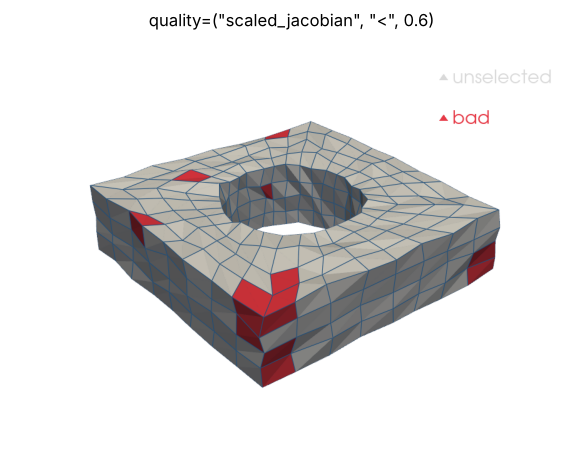

In [5]:
part = mp.select(part, 'east', plane=((0, 0, 0), (1, 0, 0)), mode='centroid')
render_cells(part, 'east', "plane=((0,0,0), (1,0,0)), mode='centroid'")

rng = np.random.default_rng(3)
jittered = part.copy()
jittered.points = jittered.points + rng.normal(scale=0.006, size=jittered.points.shape)
q = np.concatenate([a.ravel() for a in mp.attach_quality(jittered).cell_data['quality:scaled_jacobian']])
jittered, bad = mp.select(jittered, 'bad', quality=('scaled_jacobian', '<', 0.6), return_report=True)
jittered, bad_east = mp.select(jittered, 'bad_east', quality=('scaled_jacobian', '<', 0.6),
                                plane=((0, 0, 0), (1, 0, 0)), mode='centroid', return_report=True)
print('scaled Jacobian < 0.6: %d cells, %d of them east' % (bad['num_selected'], bad_east['num_selected']))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(q, bins=40, color='#3b82f6')
ax.axvline(0.6, color='#e63946', lw=2, label='threshold')
ax.set(title='scaled Jacobian of the jittered part', xlabel='scaled Jacobian', ylabel='cells')
ax.legend()
plt.tight_layout()
plt.show()
render_cells(jittered, 'bad', 'quality=("scaled_jacobian", "<", 0.6)')

## Loose parts and interfaces

`component=k` takes the k-th node-connected part. And cell regions are what `find_interface` matches: two halves selected by a plane meet across the faces at `x = 0`.

In [6]:
washer = mp.extrude(mp.annulus(0.3, 0.45, 32, 2, center=(0.0, 0.0, 0.5)), (0.0, 0.0, 0.05))
washer.regions = []
both = mp.merge([part, washer])
for k in range(2):
    _, rep = mp.select(both, 'part%d' % k, component=k, return_report=True)
    print('component %d: %d cells (of %d components)' % (k, rep['num_selected'], rep['num_components']))

west = mp.select(part, 'west', plane=((0, 0, 0), (-1, 0, 0)), mode='centroid')
_, report = mp.find_interface(west, 'west', 'east', return_report=True)
print('find_interface(west, east): %d face pairs, area %.4f' % (report['num_pairs'], report['area']))

component 0: 512 cells (of 2 components)
component 1: 64 cells (of 2 components)
find_interface(west, east): 32 face pairs, area 0.1250


## Elsewhere

The same selection is on both CLIs (`meshioplusplus select IN OUT --name inlet --kind side --seed 0,0,-1`), the `Select` pipeline step, the MCP tool `select`, and the C (`mio_select`), Fortran and Julia (`select_region`), R (`mio_select`) and WebAssembly (`selectRegion`) bindings.